## Experiment: pooled t-test and confidence interval from raw data.

In [1]:
import numpy as np
from scipy import stats

# Independent samples; the numbers are illustrative.
group_1 = np.array([21, 24, 23, 26, 25, 22, 24, 27], dtype=float)
group_2 = np.array([19, 20, 22, 21, 23, 20, 21, 22, 19, 20], dtype=float)

n1, n2 = len(group_1), len(group_2)
mean1, mean2 = np.mean(group_1), np.mean(group_2)
s1 = np.std(group_1, ddof=1)
s2 = np.std(group_2, ddof=1)

pooled_var = ((n1 - 1) * s1**2 + (n2 - 1) * s2**2) / (n1 + n2 - 2)
sp = np.sqrt(pooled_var)
se = sp * np.sqrt(1 / n1 + 1 / n2)
difference = mean1 - mean2
df = n1 + n2 - 2

statistic = difference / se
p_value = 2 * stats.t.sf(abs(statistic), df=df)
critical = stats.t.ppf(0.975, df=df)
ci = (difference - critical * se, difference + critical * se)

software_result = stats.ttest_ind(group_1, group_2, equal_var=True)

print(f"Difference in means: {difference:.3f}")
print(f"Pooled standard deviation: {sp:.3f}")
print(f"Estimated standard error: {se:.3f}")
print(f"t({df}) = {statistic:.4f}, two-sided p = {p_value:.5f}")
print(f"95% CI: ({ci[0]:.3f}, {ci[1]:.3f})")
print("SciPy result:", software_result)

# Experiment: add the same constant to both groups.
# What happens to the difference, t-statistic, and p-value?

Difference in means: 3.300
Pooled standard deviation: 1.660
Estimated standard error: 0.787
t(16) = 4.1905, two-sided p = 0.00069
95% CI: (1.631, 4.969)
SciPy result: TtestResult(statistic=4.190476190476191, pvalue=0.0006921443439425509, df=16.0)


## Experiment: computing pooled tests from summary statistics.

In [2]:
import numpy as np
from scipy import stats

# Independently reported sample summaries.
mean1, sd1, n1 = 52.0, 8.0, 30
mean2, sd2, n2 = 48.0, 7.5, 35

result = stats.ttest_ind_from_stats(
    mean1=mean1, std1=sd1, nobs1=n1,
    mean2=mean2, std2=sd2, nobs2=n2,
    equal_var=True
)

pooled_var = ((n1 - 1) * sd1**2 + (n2 - 1) * sd2**2) / (n1 + n2 - 2)
se = np.sqrt(pooled_var) * np.sqrt(1 / n1 + 1 / n2)
df = n1 + n2 - 2

# Reconstruct the two-sided confidence interval for mu1 - mu2.
difference = mean1 - mean2
margin = stats.t.ppf(0.975, df) * se

print(f"t({df}) = {result.statistic:.4f}")
print(f"Two-sided p-value = {result.pvalue:.5f}")
print(f"95% CI = ({difference - margin:.3f}, {difference + margin:.3f})")

# The sign of t determines which tail is relevant.
right_p = stats.t.sf(result.statistic, df)
left_p = stats.t.cdf(result.statistic, df)
print(f"H1: mu1 > mu2: p = {right_p:.5f}")
print(f"H1: mu1 < mu2: p = {left_p:.5f}")

# Experiment: double both sample sizes, keeping means and SDs fixed.

t(63) = 2.0787
Two-sided p-value = 0.04173
95% CI = (0.155, 7.845)
H1: mu1 > mu2: p = 0.02086
H1: mu1 < mu2: p = 0.97914


## Experiment: visual diagnostics for two independent groups.

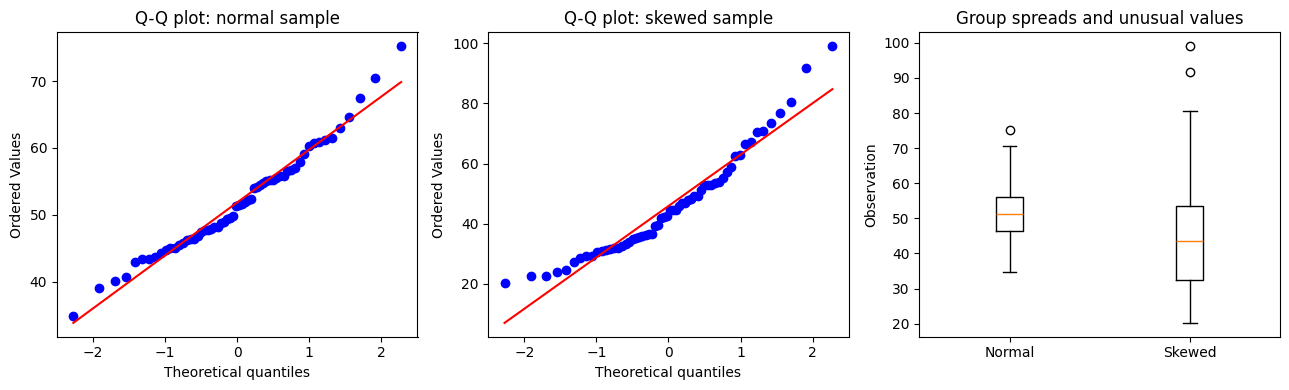

Sample SDs: 7.84413734772466 17.296658269223762


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(2026)

# One roughly normal group and one positively skewed group.
normal_group = rng.normal(loc=50, scale=8, size=60)
skewed_group = rng.lognormal(mean=np.log(45), sigma=0.35, size=60)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

stats.probplot(normal_group, dist="norm", plot=axes[0])
axes[0].set_title("Q-Q plot: normal sample")

stats.probplot(skewed_group, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot: skewed sample")

axes[2].boxplot([normal_group, skewed_group], tick_labels=["Normal", "Skewed"])
axes[2].set_title("Group spreads and unusual values")
axes[2].set_ylabel("Observation")

fig.tight_layout()
fig.savefig("../../images/pooled_t_assumptions_diagnostics.png", dpi=180, bbox_inches="tight")
plt.show()

print("Sample SDs:", np.std(normal_group, ddof=1),
      np.std(skewed_group, ddof=1))

# Experiment: increase the skewness of the second population.
# A visual diagnostic cannot prove normality or equal variances.

## Experiment: null distribution and confidence-interval coverage.

Nominal CI coverage: 95.0%
Simulated CI coverage: 94.99%
Simulated type I error: 5.01%


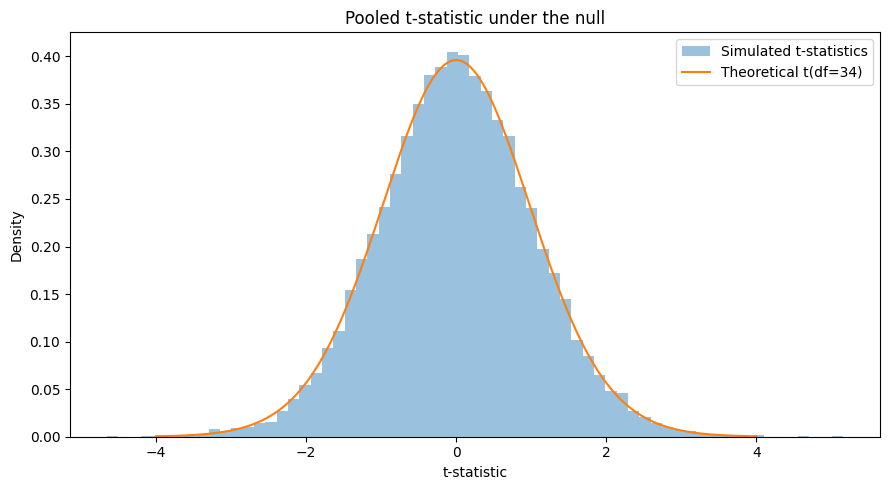

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(2026)
B = 20_000
n1, n2 = 14, 22
mu1, mu2, sigma = 5.0, 5.0, 3.0
alpha = 0.05

# Each row represents one complete independent two-group study.
x = rng.normal(mu1, sigma, size=(B, n1))
y = rng.normal(mu2, sigma, size=(B, n2))

x_bar, y_bar = x.mean(axis=1), y.mean(axis=1)
s1_sq = x.var(axis=1, ddof=1)
s2_sq = y.var(axis=1, ddof=1)
df = n1 + n2 - 2
sp_sq = ((n1 - 1) * s1_sq + (n2 - 1) * s2_sq) / df
se = np.sqrt(sp_sq * (1 / n1 + 1 / n2))
t_values = (x_bar - y_bar) / se

critical = stats.t.isf(alpha / 2, df)
ci_low = x_bar - y_bar - critical * se
ci_high = x_bar - y_bar + critical * se
true_difference = mu1 - mu2

coverage = np.mean((ci_low <= true_difference) &
                   (true_difference <= ci_high))
rejection_rate = np.mean(np.abs(t_values) > critical)

print(f"Nominal CI coverage: {1 - alpha:.1%}")
print(f"Simulated CI coverage: {coverage:.2%}")
print(f"Simulated type I error: {rejection_rate:.2%}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(t_values, bins=65, density=True, alpha=0.45,
        label="Simulated t-statistics")
grid = np.linspace(-4, 4, 500)
ax.plot(grid, stats.t.pdf(grid, df), label=f"Theoretical t(df={df})")
ax.set_xlabel("t-statistic")
ax.set_ylabel("Density")
ax.set_title("Pooled t-statistic under the null")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/pooled_t_null_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

# Experiment: increase n1 and n2; inspect the t-distribution.

## Experiment: unequal variances and unequal sample sizes.

Equal variances, balanced: pooled=0.047, Welch=0.047
Unequal variances, balanced: pooled=0.055, Welch=0.050
Larger SD in smaller group: pooled=0.291, Welch=0.053
Larger SD in larger group: pooled=0.001, Welch=0.049


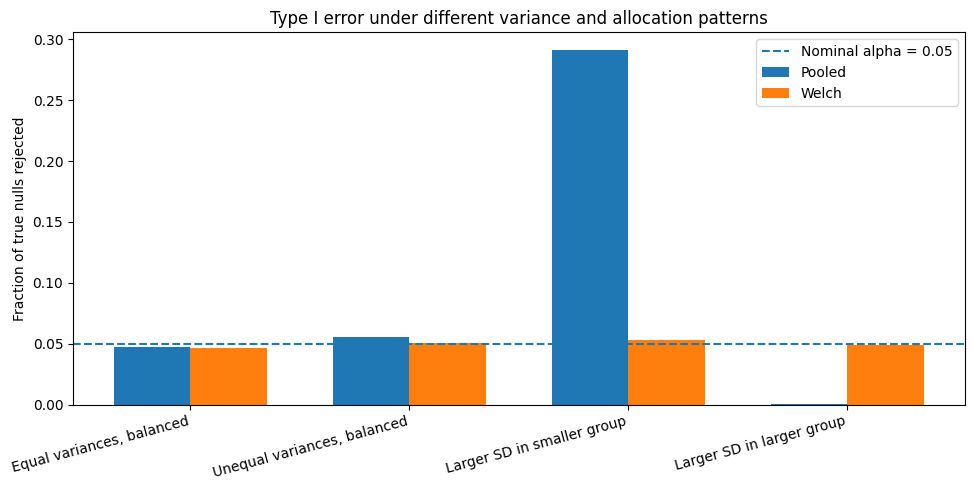

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(2026)
B = 25_000
alpha = 0.05

# Both population means equal zero: the null is true in every case.
cases = [
    (20, 20, 1.0, 1.0, "Equal variances, balanced"),
    (20, 20, 3.0, 1.0, "Unequal variances, balanced"),
    (12, 60, 3.0, 1.0, "Larger SD in smaller group"),
    (60, 12, 3.0, 1.0, "Larger SD in larger group"),
]

pooled_rates = []
welch_rates = []
labels = []

for n1, n2, sigma1, sigma2, label in cases:
    x = rng.normal(0, sigma1, size=(B, n1))
    y = rng.normal(0, sigma2, size=(B, n2))

    pooled = stats.ttest_ind(x, y, axis=1, equal_var=True)
    welch = stats.ttest_ind(x, y, axis=1, equal_var=False)

    pooled_rate = np.mean(pooled.pvalue < alpha)
    welch_rate = np.mean(welch.pvalue < alpha)

    pooled_rates.append(pooled_rate)
    welch_rates.append(welch_rate)
    labels.append(label)
    print(f"{label}: pooled={pooled_rate:.3f}, Welch={welch_rate:.3f}")

positions = np.arange(len(cases))
width = 0.35
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(positions - width / 2, pooled_rates, width, label="Pooled")
ax.bar(positions + width / 2, welch_rates, width, label="Welch")
ax.axhline(alpha, linestyle="--", label="Nominal alpha = 0.05")
ax.set_xticks(positions, labels, rotation=15, ha="right")
ax.set_ylabel("Fraction of true nulls rejected")
ax.set_title("Type I error under different variance and allocation patterns")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/pooled_t_unequal_variances.png", dpi=180, bbox_inches="tight")
plt.show()

# Experiment: interchange group variances or sample sizes.

## Experiment: power, sample size, and balanced allocation.

Power with 40 observations per group: 0.598
n1=40, n2=40: power=0.598
n1=20, n2=60: power=0.481
n1=10, n2=70: power=0.309


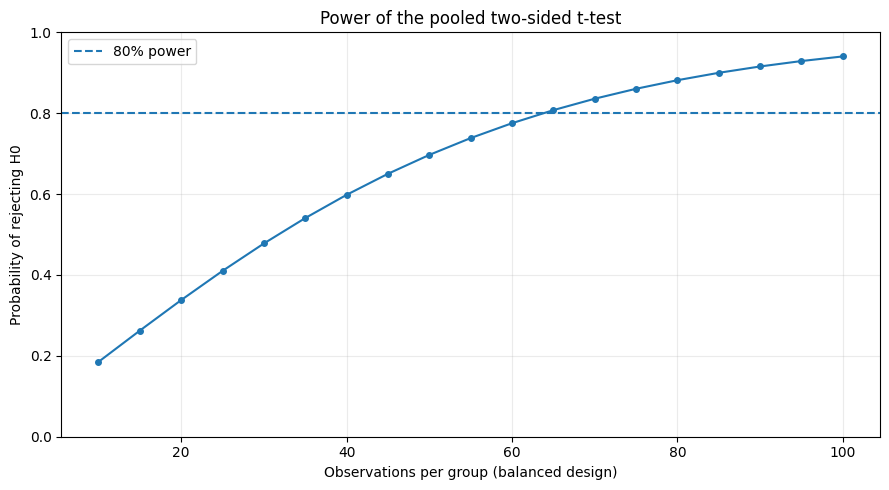

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import nct, t

alpha = 0.05
sigma = 1.0
delta = 0.5
sample_sizes = np.arange(10, 101, 5)  # Per group.


def two_sample_power(n1, n2, difference, sigma, alpha=0.05):
    df = n1 + n2 - 2
    nc = difference / (sigma * np.sqrt(1 / n1 + 1 / n2))
    cutoff = t.isf(alpha / 2, df)
    return nct.cdf(-cutoff, df, nc) + nct.sf(cutoff, df, nc)


power = [
    two_sample_power(n, n, delta, sigma, alpha)
    for n in sample_sizes
]

print("Power with 40 observations per group:",
      round(two_sample_power(40, 40, delta, sigma), 3))

# Compare group allocations with the same total sample size.
for n1, n2 in [(40, 40), (20, 60), (10, 70)]:
    result = two_sample_power(n1, n2, delta, sigma)
    print(f"n1={n1}, n2={n2}: power={result:.3f}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(sample_sizes, power, marker="o", markersize=4)
ax.axhline(0.80, linestyle="--", label="80% power")
ax.set_xlabel("Observations per group (balanced design)")
ax.set_ylabel("Probability of rejecting H0")
ax.set_title("Power of the pooled two-sided t-test")
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig("../../images/pooled_t_power_sample_size.png", dpi=180, bbox_inches="tight")
plt.show()

# Experiment: double the true standard deviation.
# How does the sample size needed for 80% power change?

##  Experiment: graduate salaries and the equal-variance assumption.

Sample sizes: 50, 50
Mean salaries: 47262.42, 35825.55 EUR
Sample SDs: 9576.16, 7200.97 EUR
Mean difference (M - F): 11436.87 EUR
Pooled t(98) = 6.7496
Pooled two-sided p-value = 1.0504e-09
Pooled 95% CI: (8074.30, 14799.44) EUR
Welch two-sided p-value = 1.3503e-09


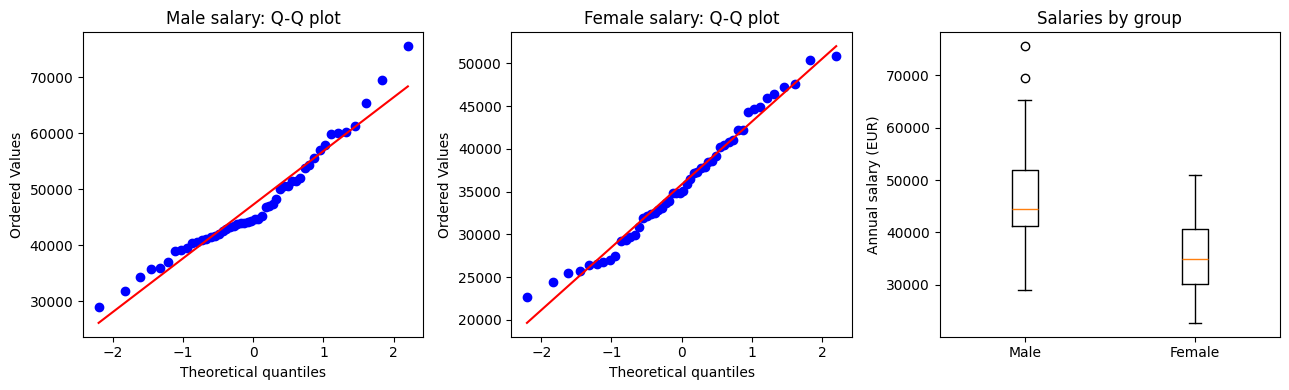

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

url = "https://userpage.fu-berlin.de/soga/data/raw-data/students.csv"
students = pd.read_csv(url)

required = {"graduated", "gender", "salary"}
missing = required.difference(students.columns)
if missing:
    raise KeyError(f"Missing dataset columns: {sorted(missing)}")

# Restrict to graduates, and explicitly remove unavailable salaries.
graduates = students.loc[
    students["graduated"] == 1, ["gender", "salary"]
].copy()
graduates["salary"] = pd.to_numeric(graduates["salary"], errors="coerce")
graduates = graduates.dropna(subset=["gender", "salary"])

male_pool = graduates.loc[graduates["gender"] == "Male", "salary"]
female_pool = graduates.loc[graduates["gender"] == "Female", "salary"]

if min(len(male_pool), len(female_pool)) < 50:
    raise ValueError("The dataset needs at least 50 available salaries per group")

# Independent subsamples selected reproducibly from each group.
male = male_pool.sample(n=50, random_state=9).to_numpy(dtype=float)
female = female_pool.sample(n=50, random_state=9).to_numpy(dtype=float)

n1, n2 = len(male), len(female)
m1, m2 = male.mean(), female.mean()
s1, s2 = male.std(ddof=1), female.std(ddof=1)
df = n1 + n2 - 2
sp = np.sqrt(((n1 - 1) * s1**2 + (n2 - 1) * s2**2) / df)
se = sp * np.sqrt(1 / n1 + 1 / n2)
margin = stats.t.isf(0.025, df) * se
ci = (m1 - m2 - margin, m1 - m2 + margin)

pooled = stats.ttest_ind(male, female, equal_var=True)
welch = stats.ttest_ind(male, female, equal_var=False)

print(f"Sample sizes: {n1}, {n2}")
print(f"Mean salaries: {m1:.2f}, {m2:.2f} EUR")
print(f"Sample SDs: {s1:.2f}, {s2:.2f} EUR")
print(f"Mean difference (M - F): {m1 - m2:.2f} EUR")
print(f"Pooled t({df}) = {pooled.statistic:.4f}")
print(f"Pooled two-sided p-value = {pooled.pvalue:.5g}")
print(f"Pooled 95% CI: ({ci[0]:.2f}, {ci[1]:.2f}) EUR")
print(f"Welch two-sided p-value = {welch.pvalue:.5g}")

# Visual diagnostics; these do not verify the model assumptions.
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
stats.probplot(male, dist="norm", plot=axes[0])
axes[0].set_title("Male salary: Q-Q plot")
stats.probplot(female, dist="norm", plot=axes[1])
axes[1].set_title("Female salary: Q-Q plot")
axes[2].boxplot([male, female], tick_labels=["Male", "Female"])
axes[2].set_title("Salaries by group")
axes[2].set_ylabel("Annual salary (EUR)")
fig.tight_layout()
fig.savefig("../../images/pooled_t_graduate_salary_diagnostics.png",
            dpi=180, bbox_inches="tight")
plt.show()

# Experiment: compare results with the full groups (without subsampling).
# Do not interpret an observational difference as a causal effect.